In [28]:
# Setup: import libraries

!pip install -q opencv-python
import cv2, numpy as np
from google.colab.patches import cv2_imshow
from google.colab import files

Saving traffic.jpg to traffic.jpg


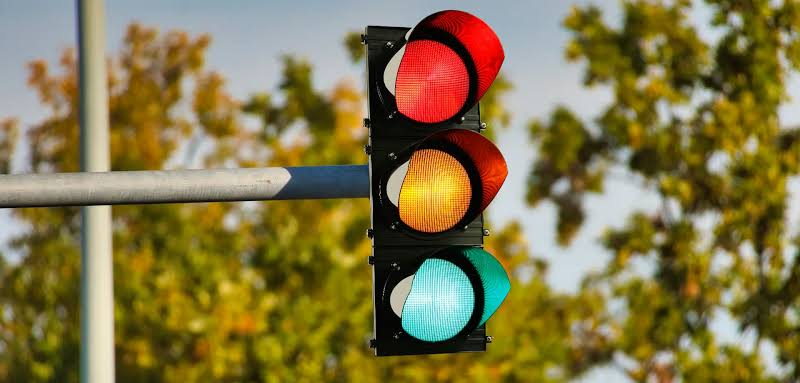


Loaded: traffic.jpg | Shape (H, W, C): (383, 800, 3) | Type: uint8


In [29]:
# Load Image A (used for color masking)

uploaded = files.upload()

fname1 = list(uploaded.keys())[0]

img_mask_bgr = cv2.imread(fname1)

assert img_mask_bgr is not None, "Image failed to load. Please upload a colored photo."
assert img_mask_bgr.ndim == 3 and img_mask_bgr.shape[2] == 3 , "Image failed to load. Please upload a colored photo.(3 channels)"

cv2_imshow(img_mask_bgr)
print(f"\nLoaded: {fname1} | Shape (H, W, C): {img_mask_bgr.shape} | Type: {img_mask_bgr.dtype}")

Saving grayscale.jpg to grayscale.jpg


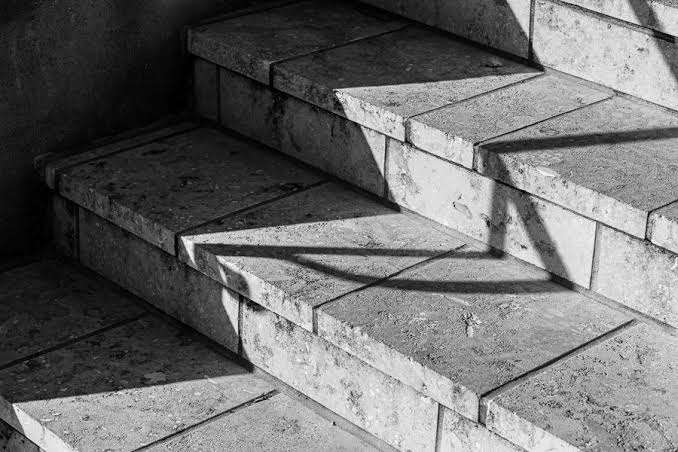


Loaded: grayscale.jpg | Shape (H, W, C): (452, 678, 3) | Type: uint8


In [30]:
# Load Image B (used for intensity transformations)

uploaded = files.upload()

fname2 = list(uploaded.keys())[0]

img_tone_bgr = cv2.imread(fname2)

assert img_tone_bgr is not None, "Image failed to load. Please upload a colored photo."
assert img_tone_bgr.ndim == 3 and img_tone_bgr.shape[2] == 3 , "Image failed to load. Please upload a colored photo.(3 channels)"

cv2_imshow(img_tone_bgr)
print(f"\nLoaded: {fname2} | Shape (H, W, C): {img_tone_bgr.shape} | Type: {img_tone_bgr.dtype}")

**Scenario: “I only want to work with colors easily.”**

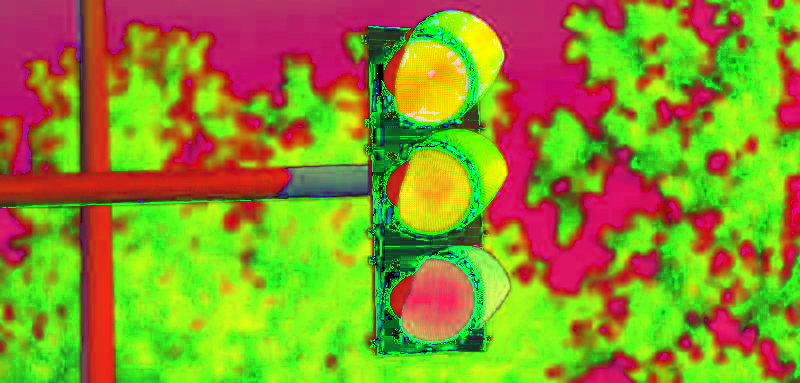

In [31]:
# Convert Image A from BGR to HSV (separates color from brightness)

hsvA = cv2.cvtColor(img_mask_bgr, cv2.COLOR_BGR2HSV)

cv2_imshow(hsvA) # just to see something is produced

**Scenario: “Find red things in the picture.”**

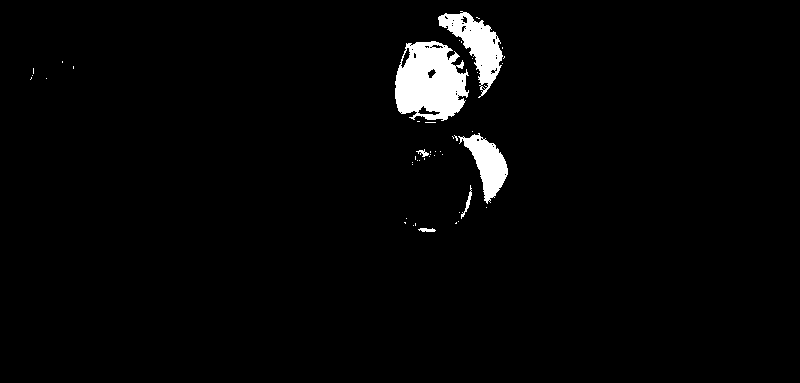

In [32]:
# Create a binary mask for red (white = red pixels)
# HSV ranges: H 0-10, S 100-255, V 100-255

lower_red = np.array([0, 100, 100])

upper_red = np.array([10, 255, 255])

mask_red = cv2.inRange(hsvA, lower_red, upper_red)

cv2_imshow(mask_red)

**Scenario: “Show only the red objects, hide the rest.”**

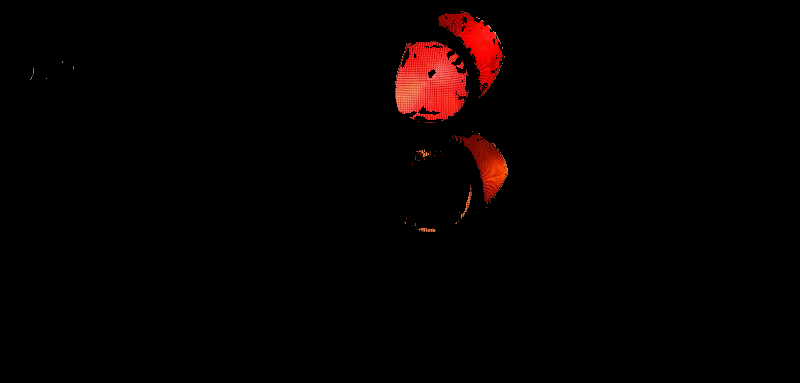

In [33]:
# Apply the mask: keep red regions, set the rest to black

red_only = cv2.bitwise_and(img_mask_bgr, img_mask_bgr, mask=mask_red)
cv2_imshow(red_only)

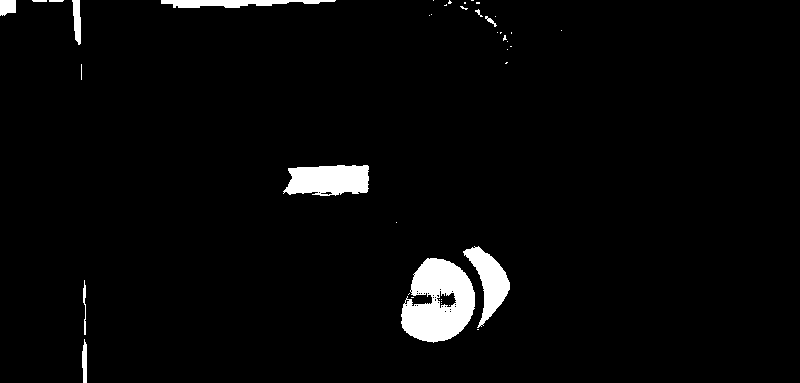

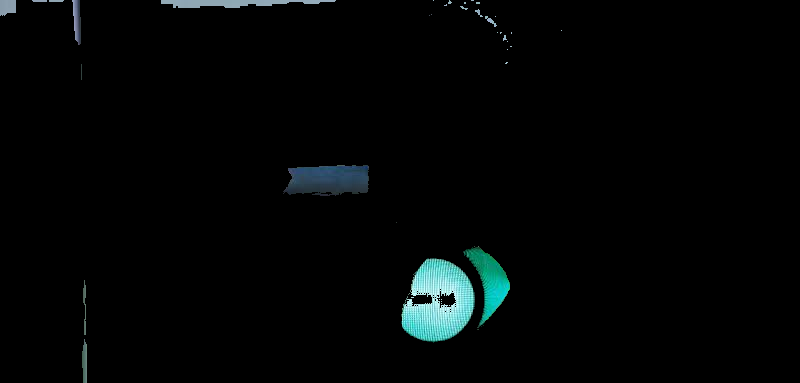

In [34]:
# Same method with a blue hue range

lower_blue = np.array([70, 50, 50])                    # H,S,V mins
upper_blue = np.array([130, 255, 255])                 # H,S,V max
mask_blue = cv2.inRange(hsvA, lower_blue, upper_blue)
cv2_imshow(mask_blue)                                  # white = blue pixels

# keep only the blue parts
blue_only = cv2.bitwise_and(img_mask_bgr, img_mask_bgr, mask=mask_blue)
cv2_imshow(blue_only)

**Scenario: “Hide red objects; show everything else.”**

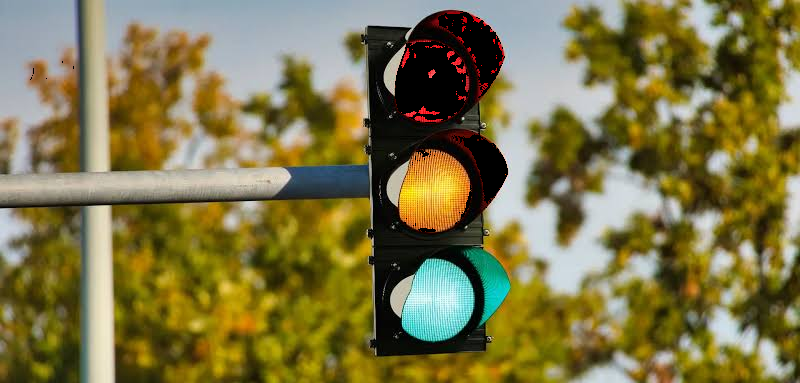

In [35]:
# Invert the mask to remove red and keep everything else

inverse_red = cv2.bitwise_not(mask_red)
no_red = cv2.bitwise_and(img_mask_bgr, img_mask_bgr, mask=inverse_red)
cv2_imshow(no_red)

# **Intensity Transformations**

**Scenario: “Create a photo negative for a cool effect.”**

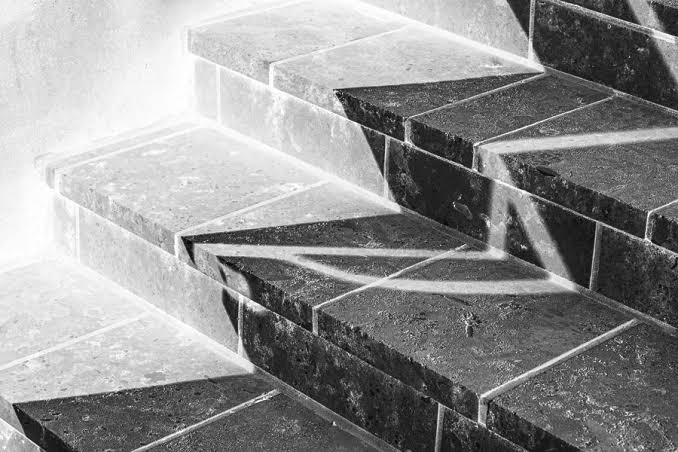

In [36]:
# Convert Image B to grayscale for intensity transformations

grayB = cv2.cvtColor(img_tone_bgr, cv2.COLOR_BGR2GRAY)

# Negative transform: s = 255 - r
negativeB = 255 - grayB
cv2_imshow(negativeB)

**Scenario: “Check one pixel to see the math.”**

In [37]:
# Compare one pixel before and after the negative transform

y, x = 50, 50 # you can pick any location

print("Original:", grayB[y, x], "| Negative:", negativeB[y, x])

Original: 32 | Negative: 223


**Scenario: “Quick visual compare: original vs negative.”**

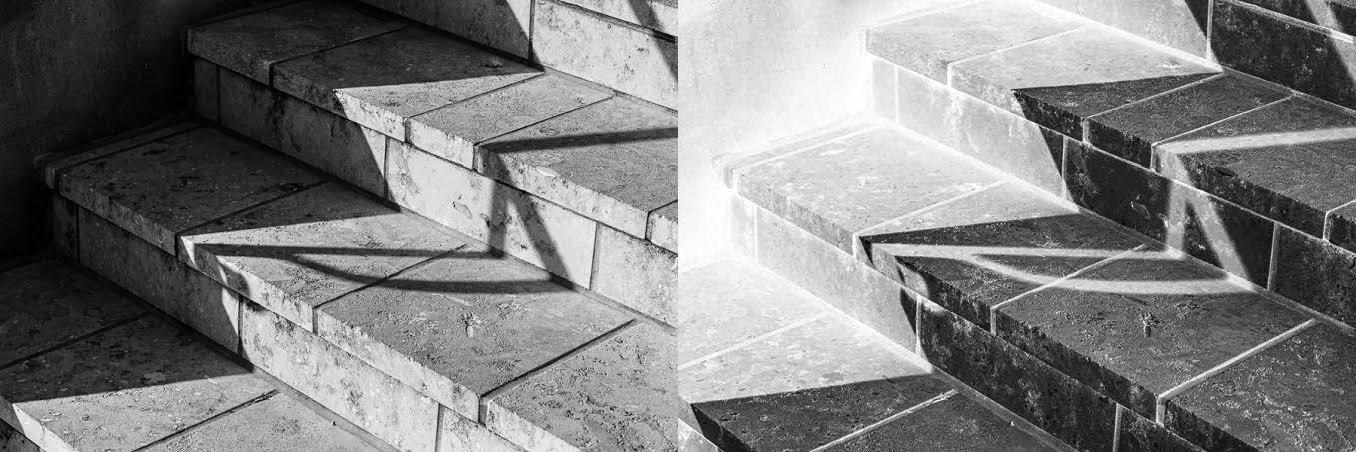

In [38]:
# Display original and negative side by side

stack_neg = np.hstack([grayB, negativeB])
cv2_imshow(stack_neg)

**Scenario: “Bright areas are fine; dark areas lack detail. Boost the darks.”**

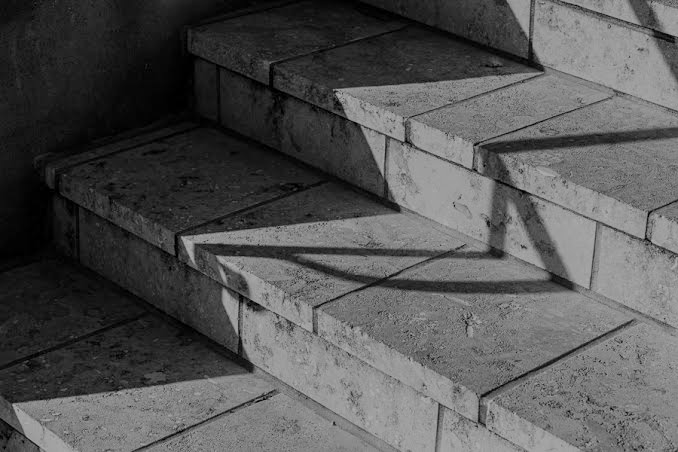

In [39]:
# Log transform: brightens dark regions, compresses bright ones
# Normalize to [0,1], apply log(1 + r), scale back to [0,255]

grayB_f = grayB.astype(np.float32) / 255.0   # scale to [0..1]
logB = np.log1p(grayB_f) * 255.0             # log(1+x) is safe at 0
logB = np.uint8(np.clip(logB, 0, 255))
cv2_imshow(logB)

**Scenario: “Show the exact change on one pixel (log).”**

In [40]:
# Compare one pixel before and after the log transform

print("Original:", grayB[y, x],"| Log:", logB[y, x])

Original: 32 | Log: 30


**Scenario: “Make the log effect a bit stronger.”**

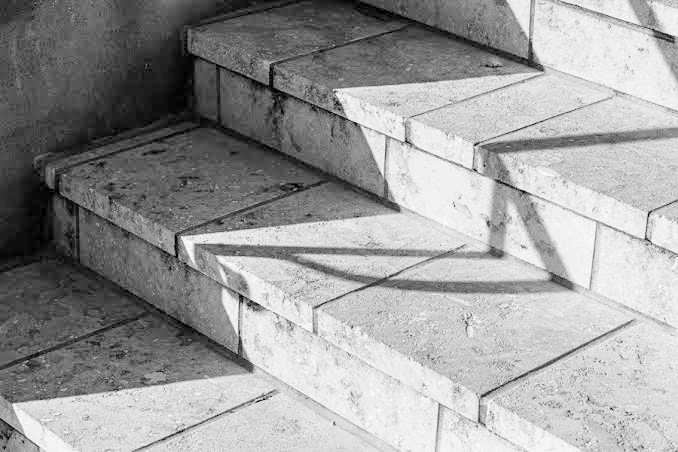

In [41]:
# Adjustable log transform (larger k = stronger boost in shadows)

k = 10.0 # try 3, 5, or 8
logB_strong = (np.log1p(k * grayB_f) / np.log1p(k)) * 255.0
logB_strong = np.uint8(np.clip(logB_strong, 0, 255))
cv2_imshow(logB_strong)

**Scenario: “Compare original vs log (side-by-side).”**

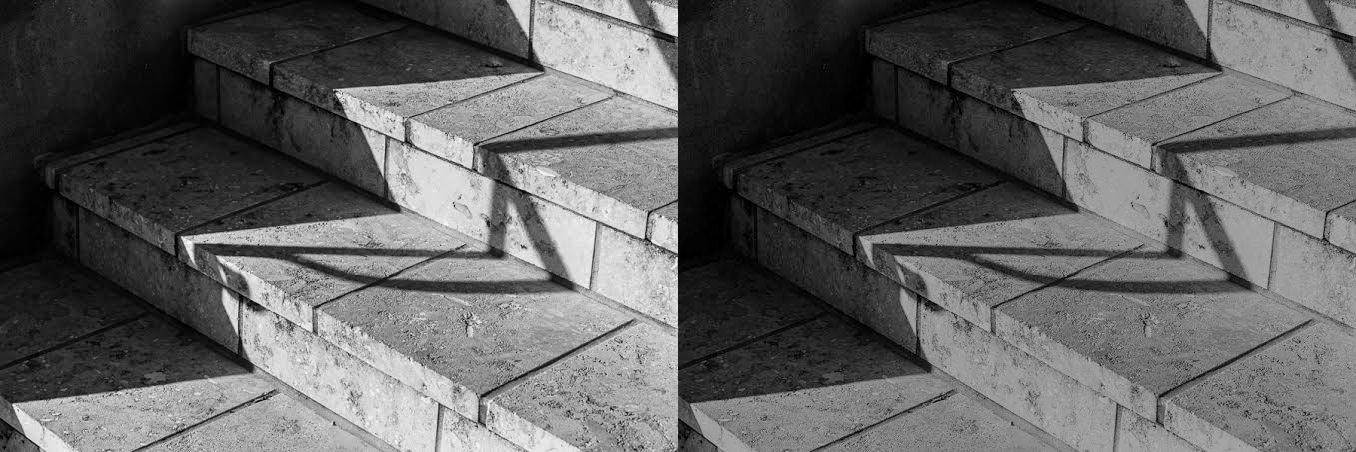

In [42]:
# Display original and log result side by side

stack_log = np.hstack([grayB, logB])
cv2_imshow(stack_log)

# **Gamma (Power-Law)**

**Scenario: “My photo is too dark—gently brighten it (gamma &lt; 1).”**

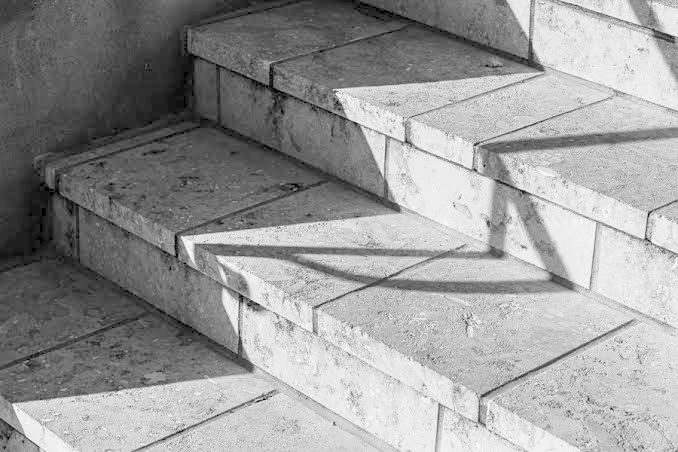

In [43]:
# Gamma correction: s = 255 * (r / 255) ** gamma
# gamma < 1 brightens the image

gamma = 0.5
gammaB_05 = np.uint8(np.clip(255.0 * (grayB_f ** gamma), 0, 255))
cv2_imshow(gammaB_05)

**Scenario: “My photo is too bright—gently darken it (gamma &gt; 1).”**

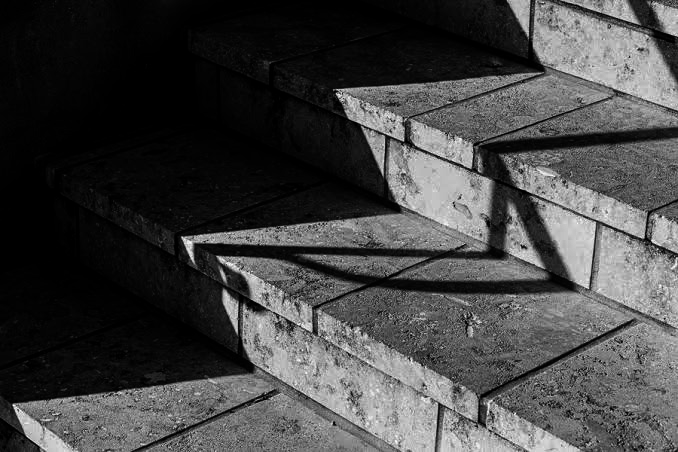

In [44]:
# gamma > 1 darkens the image

gamma = 2.0
gammaB_20 = np.uint8(np.clip(255.0 * (grayB_f ** gamma), 0, 255))

cv2_imshow(gammaB_20)

**Scenario:**

**“Try a few gamma values and pick your favorite.”**

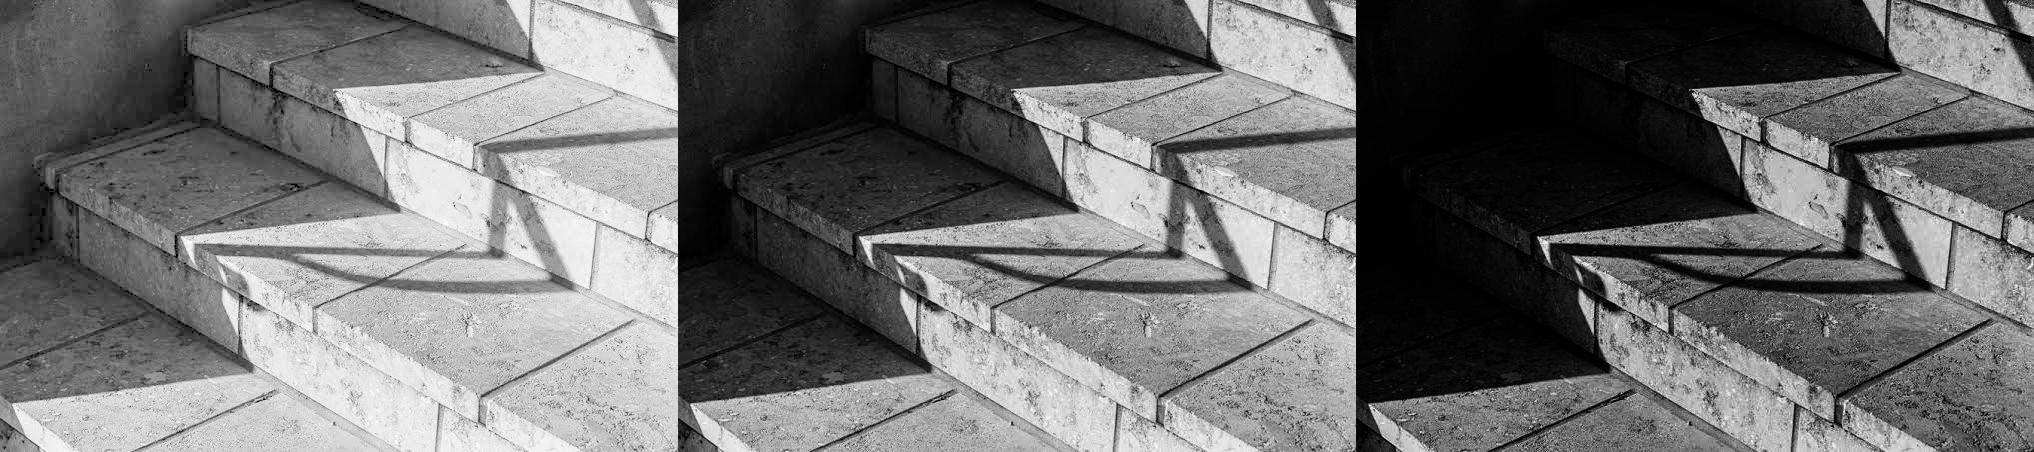

In [45]:
# Compare gamma values 0.5, 1.0 and 2.0 in one panel

gammas = [0.5, 1.0, 2.0]
imgs = [np.uint8(255.0 * (grayB_f ** g)) for g in gammas]
panel = np.hstack(imgs) # 0.5 | 1.0 | 2.0
cv2_imshow(panel)

**Scenario: “Check exact numbers for gamma brightening.”**

In [46]:
# Compare one pixel before and after gamma 0.5

print(f"Original: {grayB[y, x]} | Gamma(0.5): {imgs[0][y, x]}")

Original: 32 | Gamma(0.5): 90
